# Data Understanding for the microbiology events dastaset

In [15]:
import pandas as pd
import numpy as np
import sys
import os
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du

lab_events_df = pd.read_csv("../../data/raw/microbiology_events_codes_3.csv")
lab_events_df['subject_id'].nunique()

2616

## General info about the dataset

This section contains some general and basic informations about the dataset

In [16]:
# Shape of the dataset (rows, columns)
rows,columns = lab_events_df.shape
print(f"Rows: {rows}, Cols: {columns}")


Rows: 15587, Cols: 14


In [17]:
# Info about the dataframe
du.get_info(lab_events_df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15587 entries, 0 to 15586
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   subject_id           15587 non-null  int64  
 1   hadm_id              15587 non-null  float64
 2   chartdate            15587 non-null  object 
 3   charttime            15587 non-null  object 
 4   spec_type_desc       15587 non-null  object 
 5   test_name            15587 non-null  object 
 6   org_name             5391 non-null   object 
 7   ab_name              4820 non-null   object 
 8   dilution_text        4713 non-null   object 
 9   dilution_comparison  4711 non-null   object 
 10  dilution_value       4711 non-null   float64
 11  interpretation       4820 non-null   object 
 12  technician_id        15587 non-null  object 
 13  qc_flag              15587 non-null  object 
dtypes: float64(2), int64(1), object(11)
memory usage: 1.7+ MB


In [18]:
numeric_cols = du.get_numeric_cols(lab_events_df)
numeric_cols

['dilution_value']

In [19]:
# Column names presents in the dataset
cols = du.get_cols(lab_events_df)
cols

['subject_id',
 'hadm_id',
 'chartdate',
 'charttime',
 'spec_type_desc',
 'test_name',
 'org_name',
 'ab_name',
 'dilution_text',
 'dilution_comparison',
 'dilution_value',
 'interpretation',
 'technician_id',
 'qc_flag']

In [20]:
def get_percentage_cols_with_none(df):
    cols_with_none_info = du.get_cols_with_none(df)
    n_cols_with_none = np.count_nonzero(cols_with_none_info % 2 == 1)

    percentage_of_cols_with_none = (n_cols_with_none / len(du.get_cols(df))) * 100

    return percentage_of_cols_with_none
# Getting the percentage of columns with at least one None
print(f"Percentage of columns with at least one None value in the dataframe: {get_percentage_cols_with_none(lab_events_df):.2f} %")

Percentage of columns with at least one None value in the dataframe: 42.86 %


In [21]:
def get_none_percentage_per_cols(df):
    res = []
    for col in du.get_cols(df):
        not_none = (lab_events_df[col].count())
        none_percentage = ((rows - not_none)/rows)*100
        res.append((col, none_percentage))
    return res
# Get the percentage of None values for each columns
none_percentage_per_cols = get_none_percentage_per_cols(lab_events_df)

print("=== PERCENTAGE OF NONE PER COLUMN ===")
for col, percentage in sorted(none_percentage_per_cols, key=lambda tup: tup[1], reverse=True):
    print(f"{col}: {percentage:.2f}%")

=== PERCENTAGE OF NONE PER COLUMN ===
dilution_comparison: 69.78%
dilution_value: 69.78%
dilution_text: 69.76%
ab_name: 69.08%
interpretation: 69.08%
org_name: 65.41%
subject_id: 0.00%
hadm_id: 0.00%
chartdate: 0.00%
charttime: 0.00%
spec_type_desc: 0.00%
test_name: 0.00%
technician_id: 0.00%
qc_flag: 0.00%


## Distribution plots

### Missing value distribution

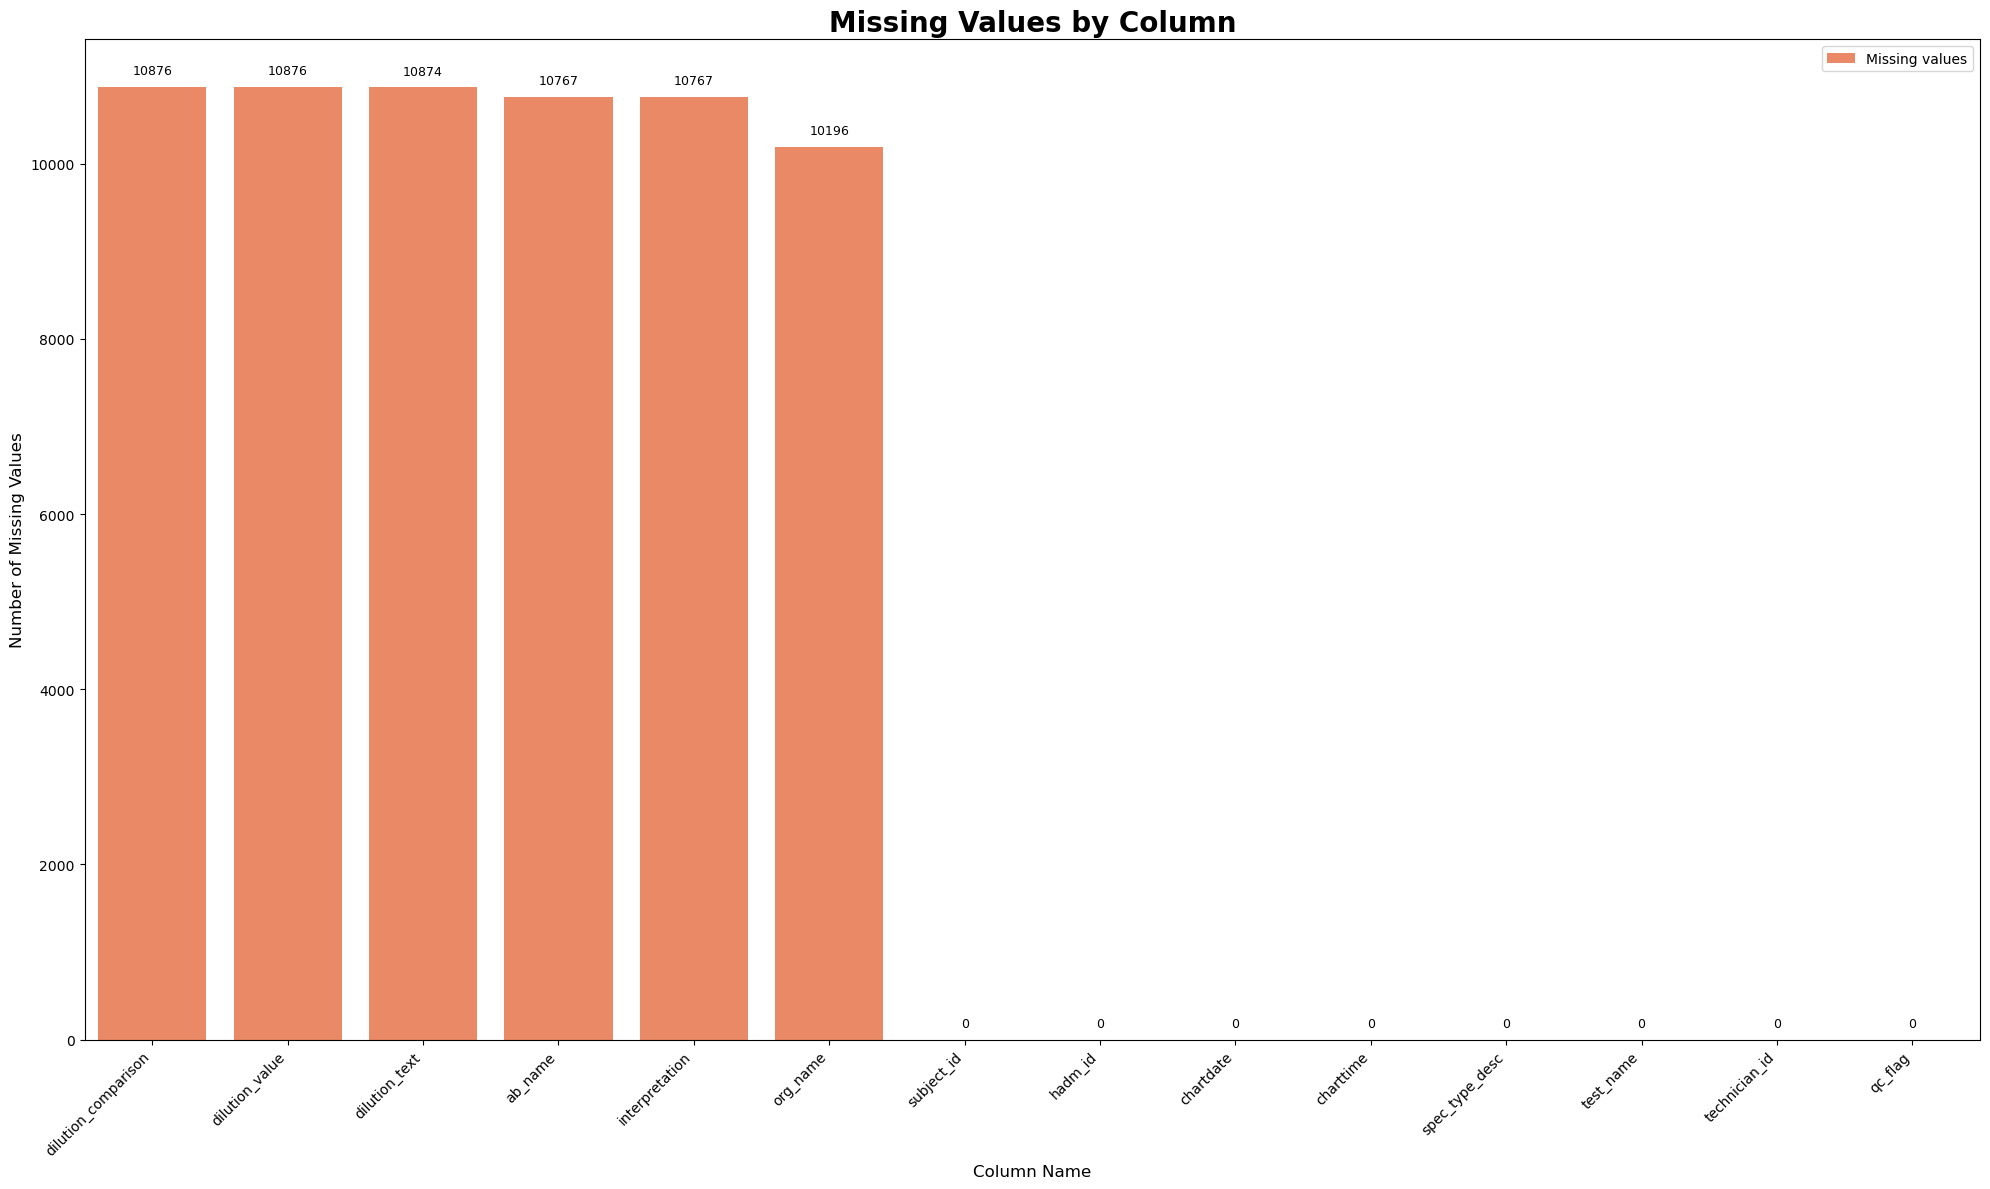

In [22]:
number_of_missing_values = lab_events_df.count()

diff = rows - number_of_missing_values

# Convert to DataFrame for easier plotting
missing_df = pd.DataFrame({
    'column': diff.index,
    'missing_count': diff.values
})

# Sort by missing count (optional, for better visualization)
missing_df = missing_df.sort_values('missing_count', ascending=False)

# Create the plot
fig, ax = plt.subplots(figsize=(20,12))

# Create barplot
sns.barplot(
    data=missing_df,
    x='column',
    y='missing_count',
    ax=ax,
    color='coral',
    label='Missing values'
)

ax.set_title('Missing Values by Column', fontsize=20, fontweight='bold')
ax.set_xlabel('Column Name', fontsize=12)
ax.set_ylabel('Number of Missing Values', fontsize=12)

# Rotate x-axis labels for readability
plt.xticks(rotation=45, ha='right')

# Add value labels on top of bars
for i, v in enumerate(missing_df['missing_count']):
    ax.text(i, v + max(missing_df['missing_count']) * 0.01, 
            str(v), ha='center', va='bottom', fontsize=9)

# Adjust layout
plt.tight_layout()
plt.show()



### Quality flag distribution plot

Text(0, 0.5, 'Count')

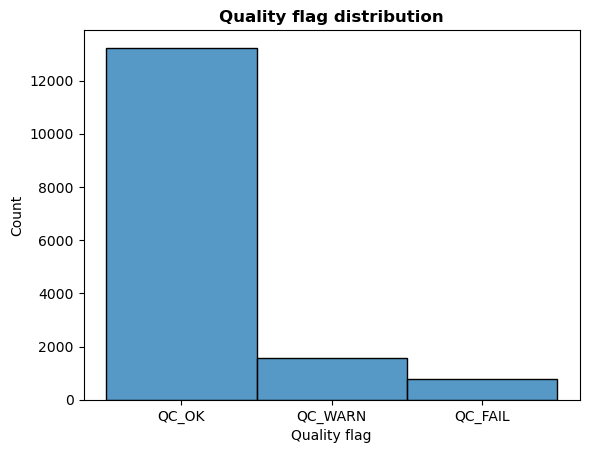

In [23]:
sns.histplot(data=lab_events_df, x='qc_flag')
plt.title("Quality flag distribution", fontweight="bold")
plt.xlabel("Quality flag")
plt.ylabel("Count")

### Organism name distribution plot

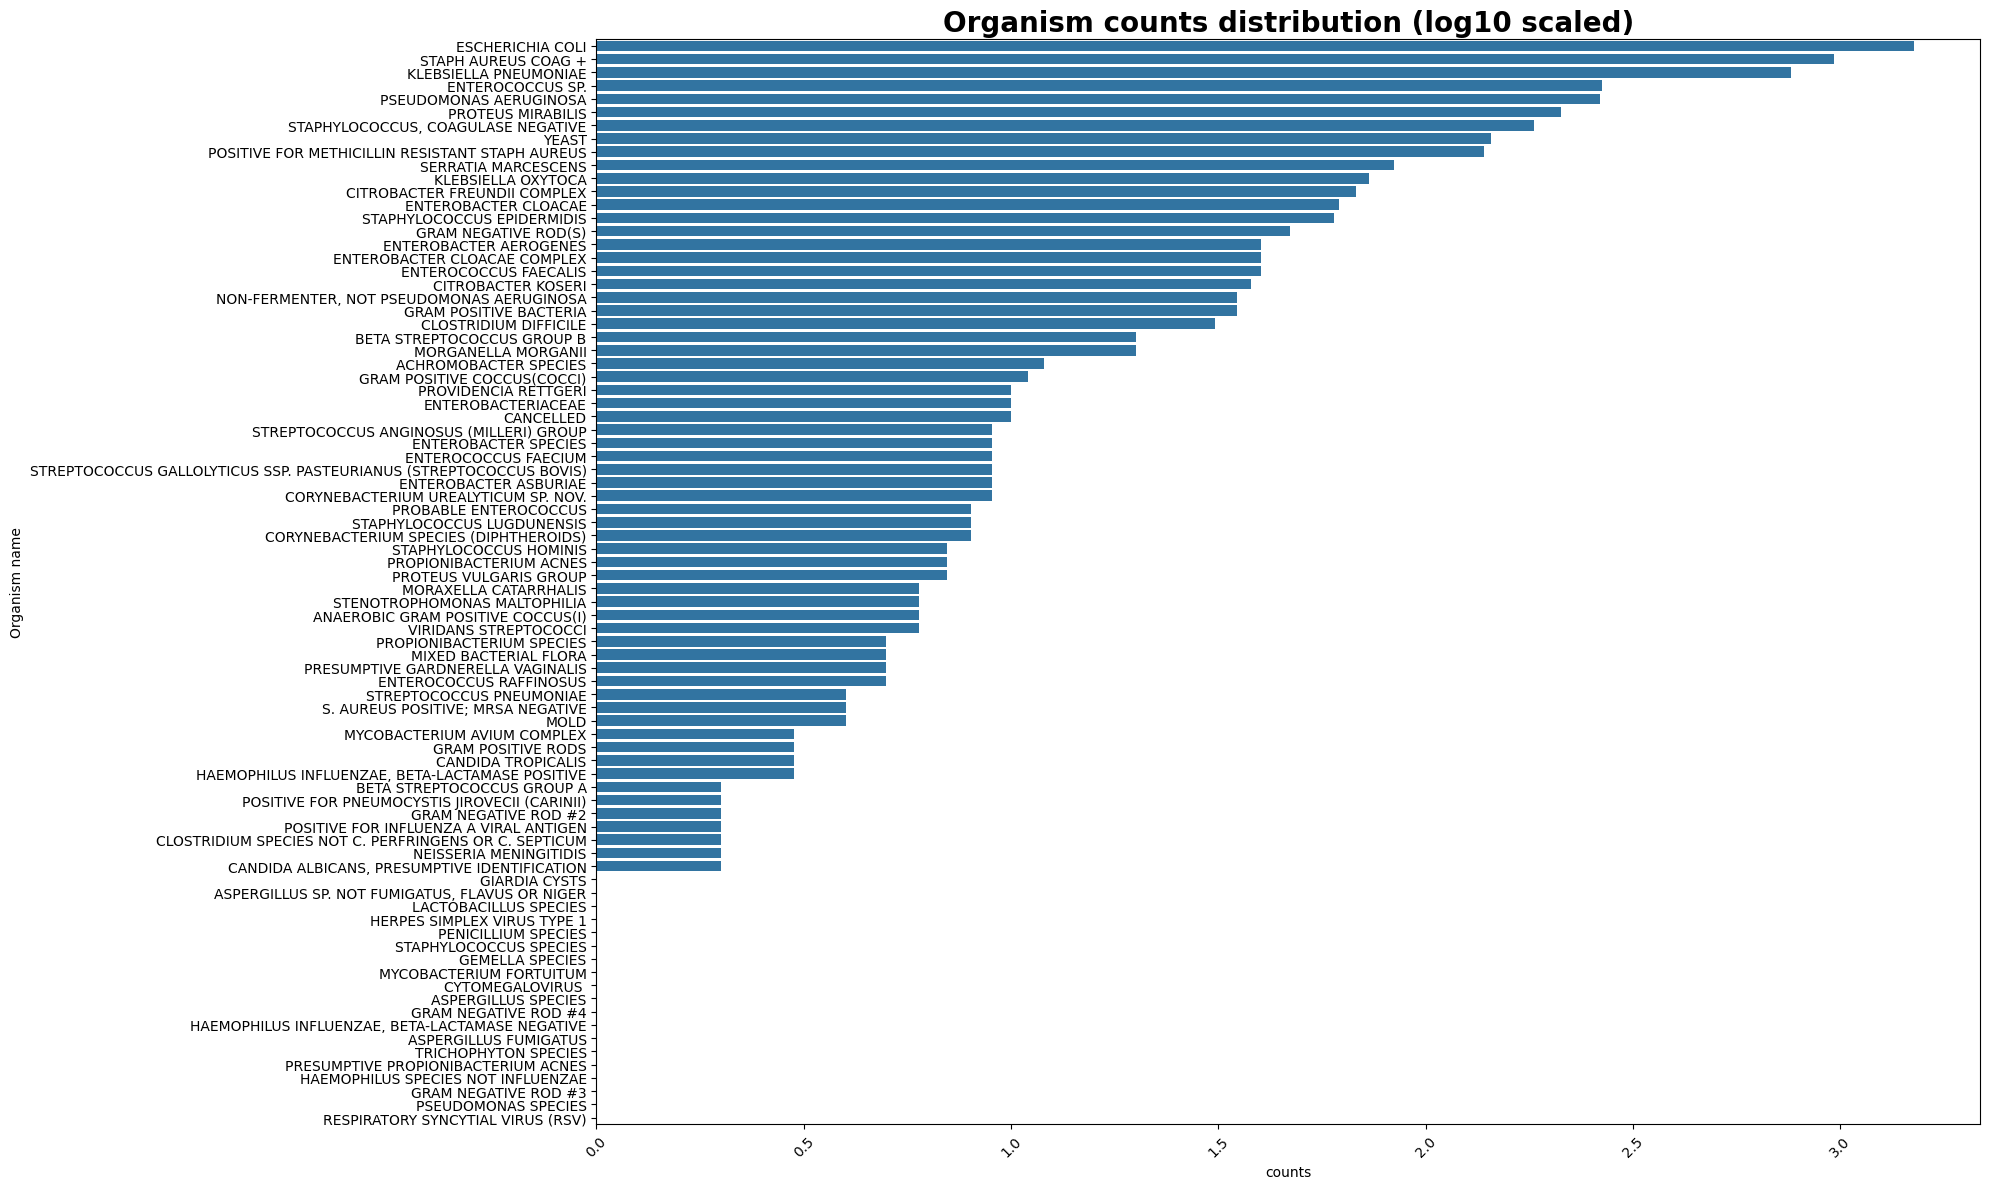

In [24]:
org_count = np.log10(lab_events_df['org_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=org_count.index, x=org_count.values)
plt.title("Organism counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Organism name")
plt.xlabel("counts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Test distribution plot

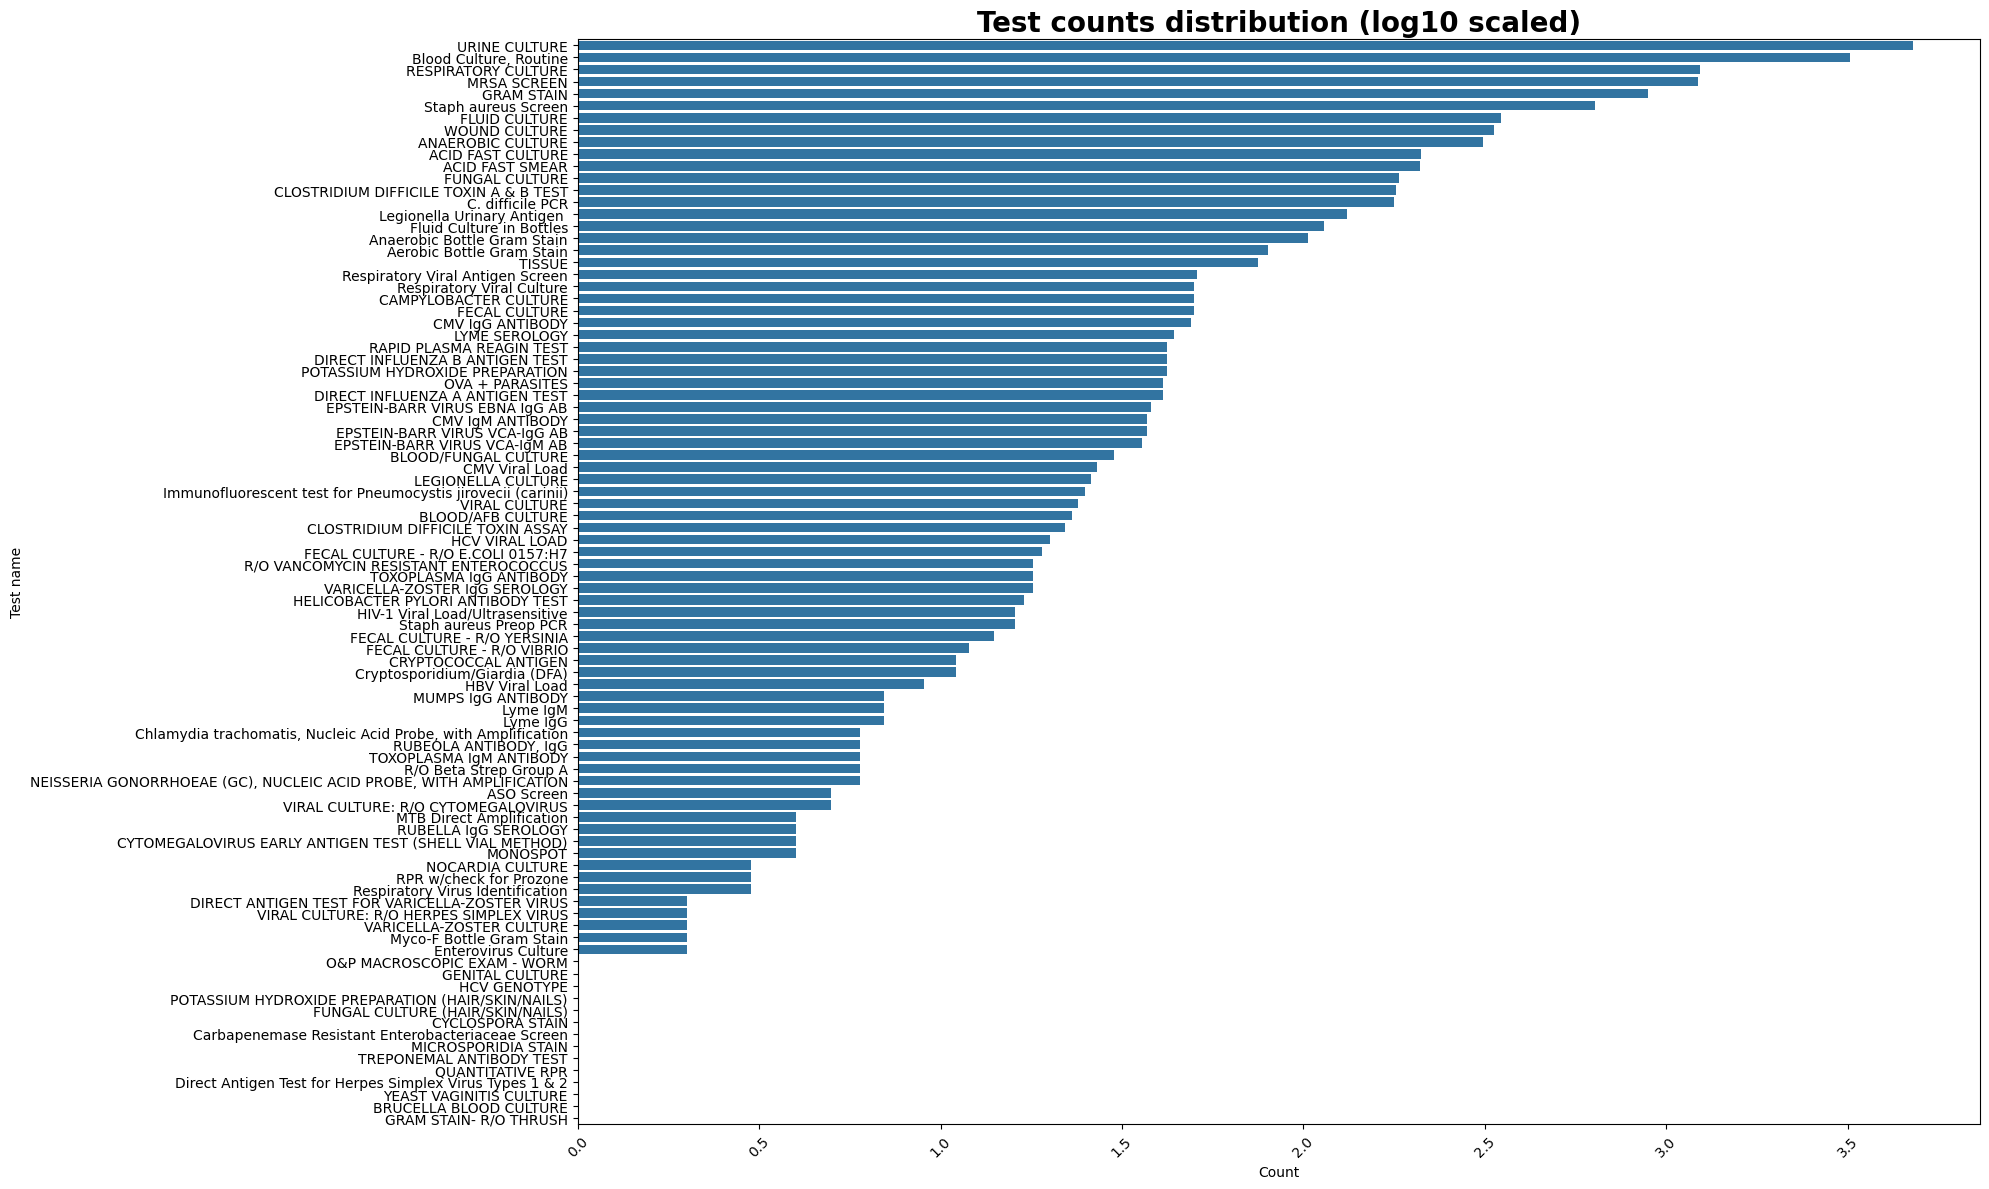

In [25]:
test_count = np.log10(lab_events_df['test_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=test_count.index, x=test_count.values)
plt.title("Test counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Test name")
plt.xlabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Antibiotic distribution plot

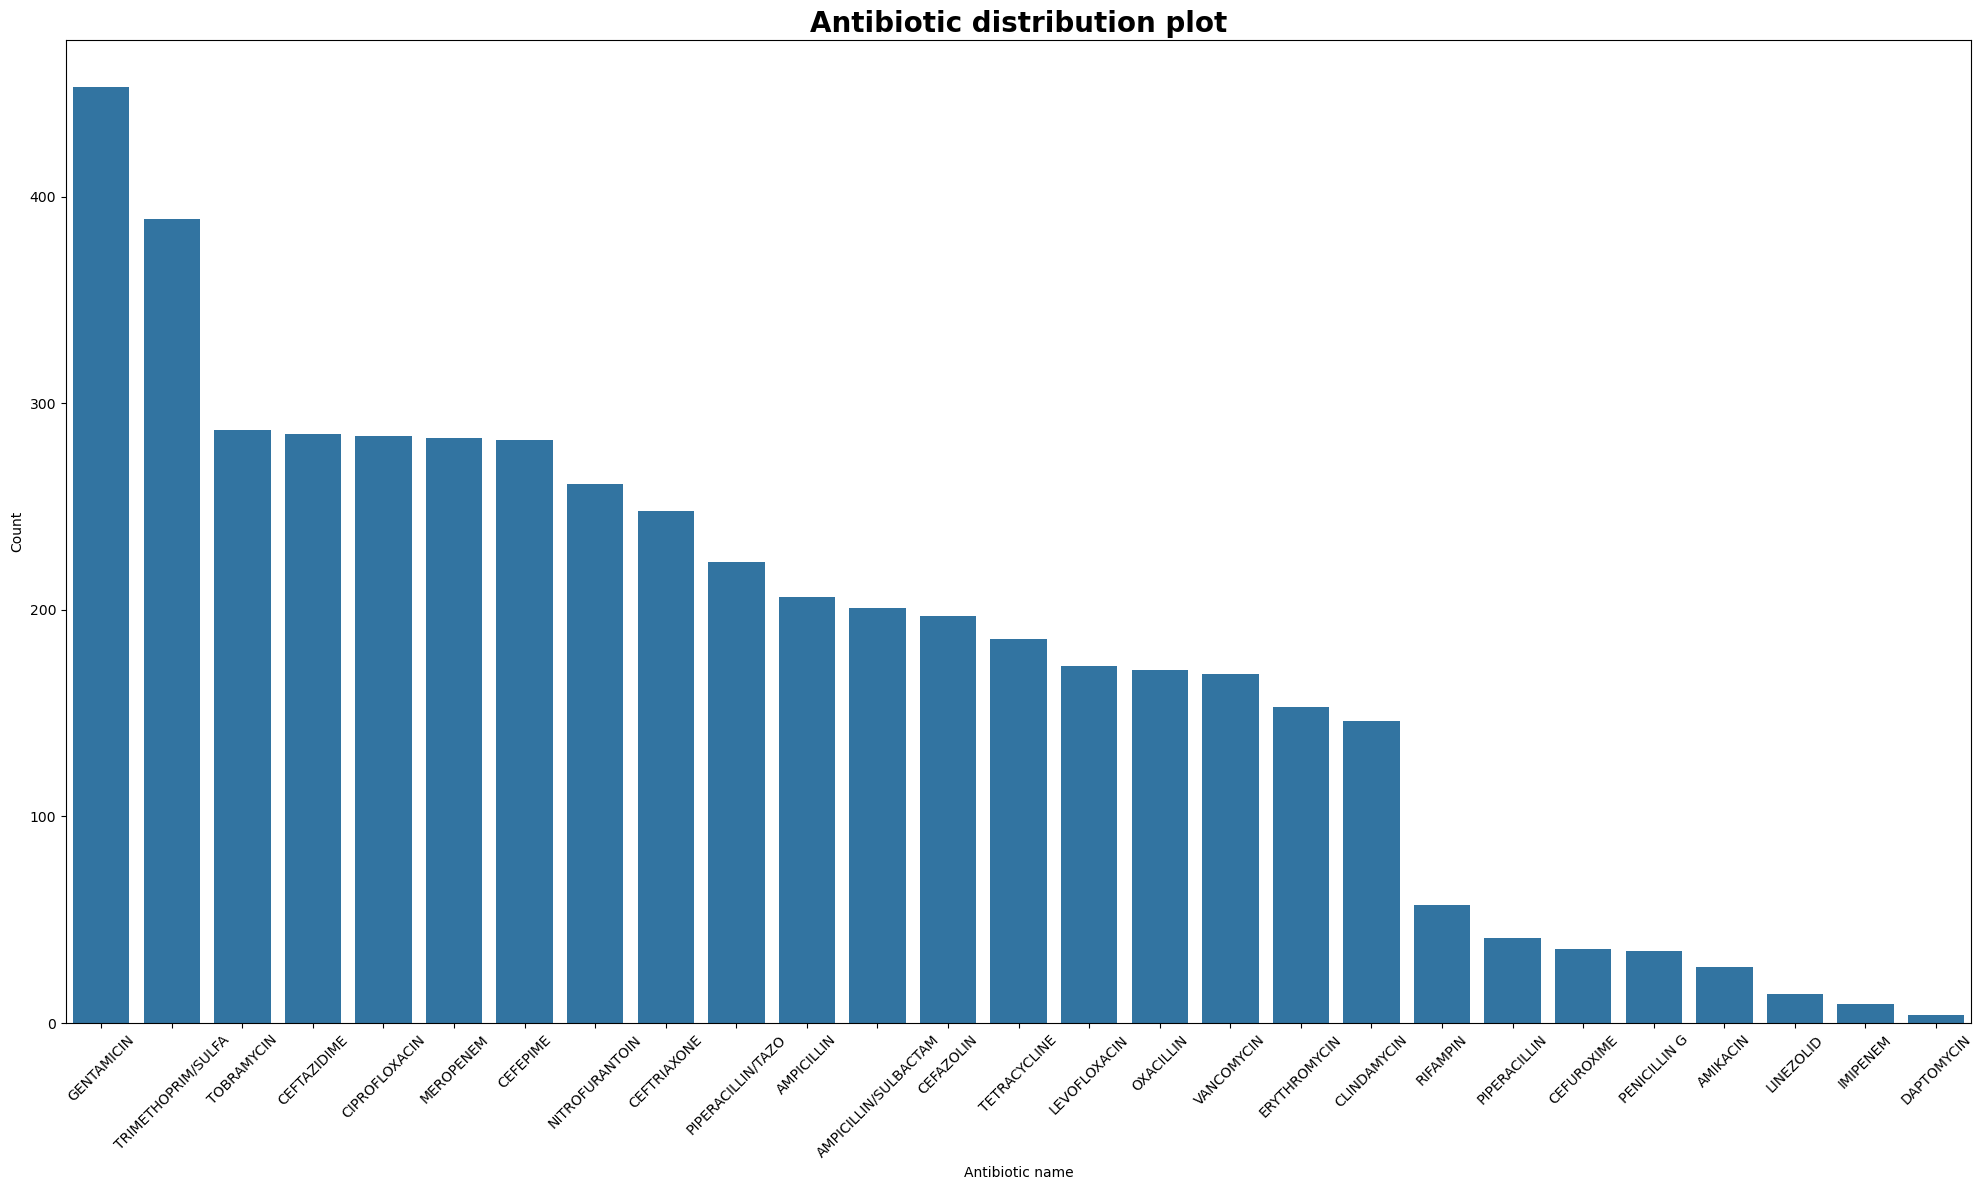

In [26]:
ab_count = lab_events_df['ab_name'].value_counts()

plt.figure(figsize=(20, 12))
sns.barplot(x=ab_count.index, y=ab_count.values)
plt.title("Antibiotic distribution plot", fontsize=20, fontweight="bold")
plt.xlabel("Antibiotic name")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

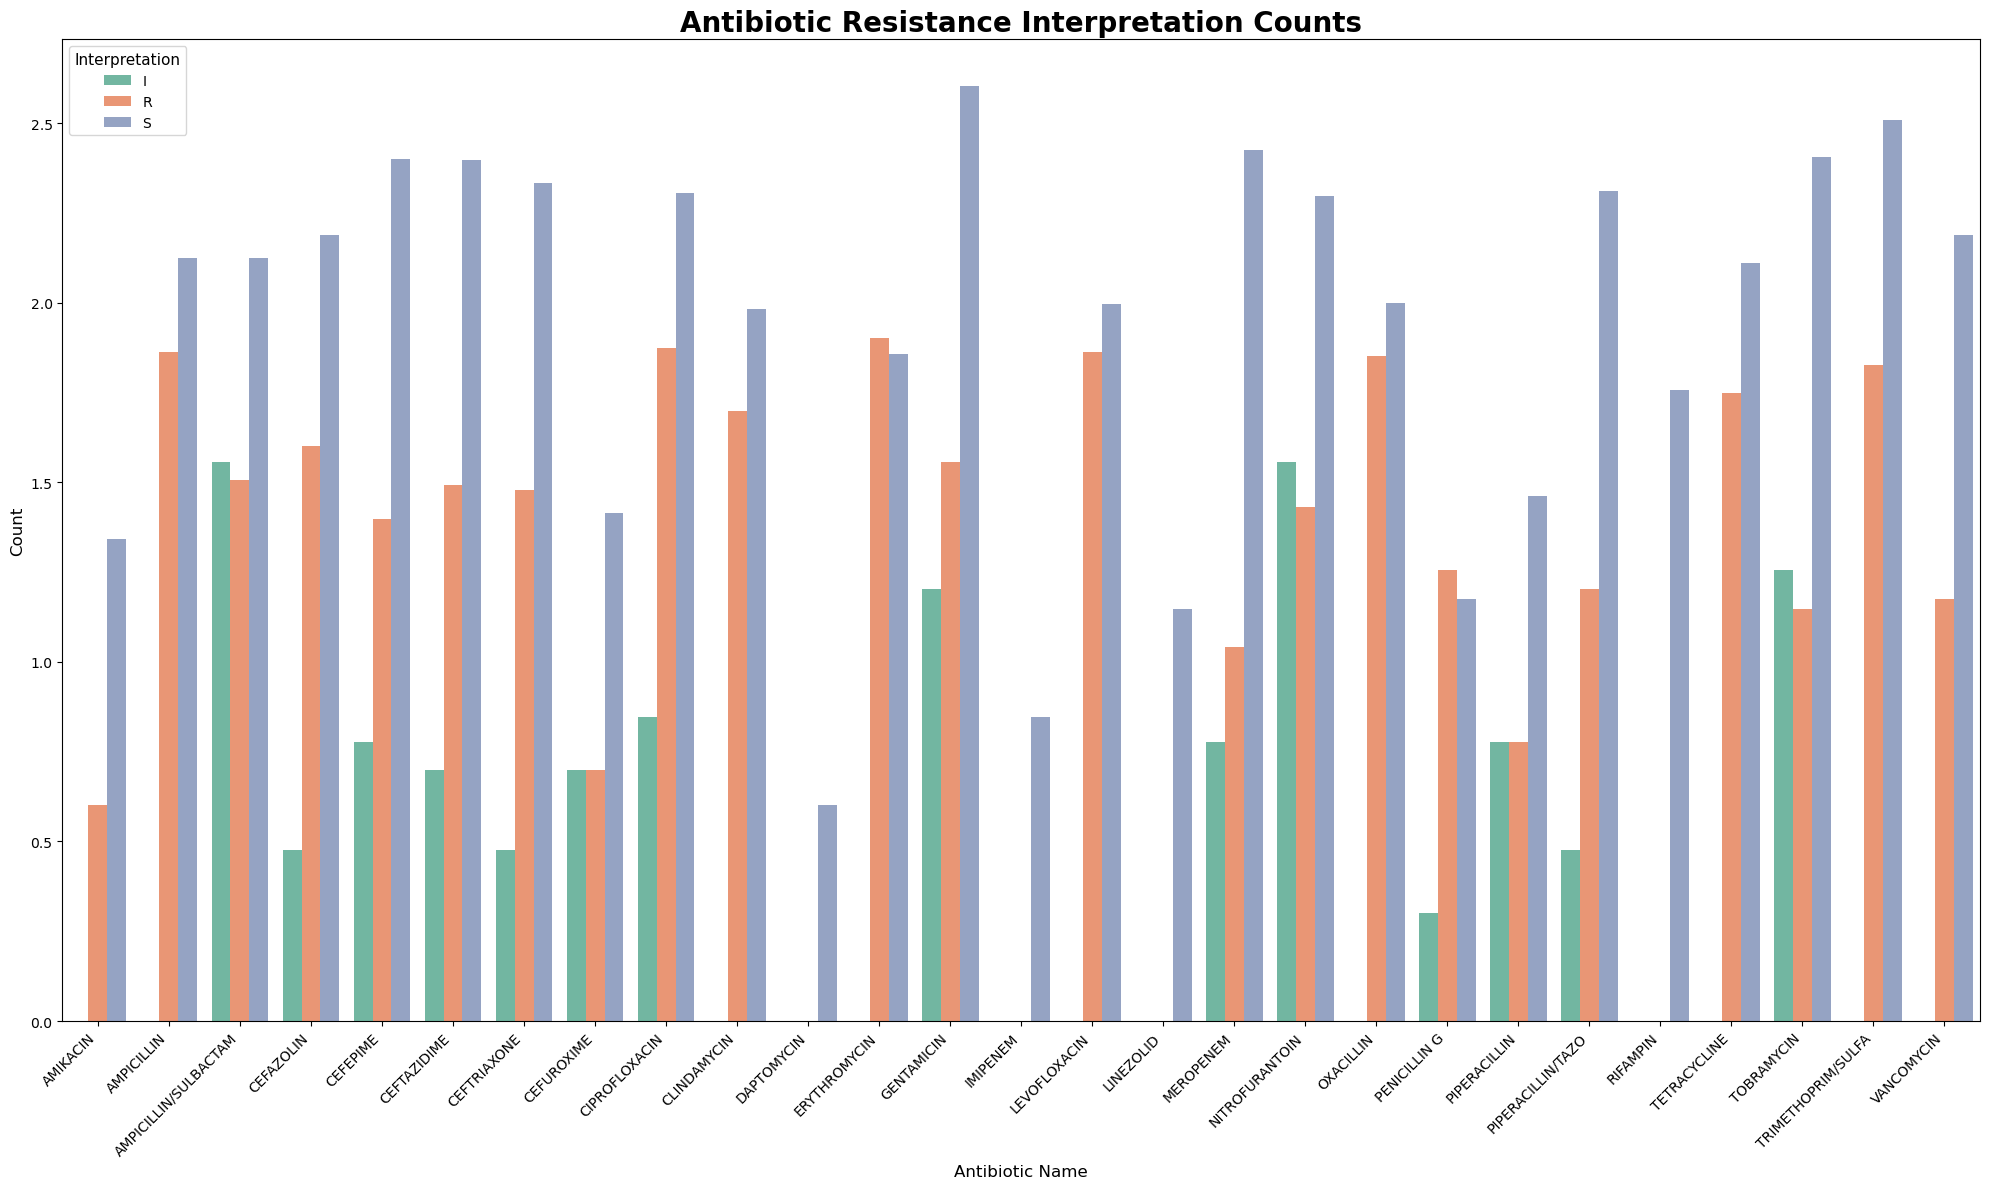

In [27]:
# Get the counts
resistant_counts = np.log10(lab_events_df.groupby("ab_name")['interpretation'].value_counts().replace(0, np.nan))
counts_df = resistant_counts.reset_index(name='count')

# Calculate average count for each interpretation to determine order
interpretation_avg = counts_df.groupby('interpretation')['count'].mean().sort_values(ascending=True)
sorted_interpretations = interpretation_avg.index.tolist()

# Create the plot
fig, ax = plt.subplots(figsize=(20,12))

# Create grouped barplot with sorted hue order
sns.barplot(
    data=counts_df,
    x='ab_name',
    y='count',
    hue='interpretation',
    ax=ax,
    palette='Set2',
    hue_order=sorted_interpretations
)

# Customize the plot
ax.set_title('Antibiotic Resistance Interpretation Counts', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibiotic Name', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Interpretation', title_fontsize=11, fontsize=10)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

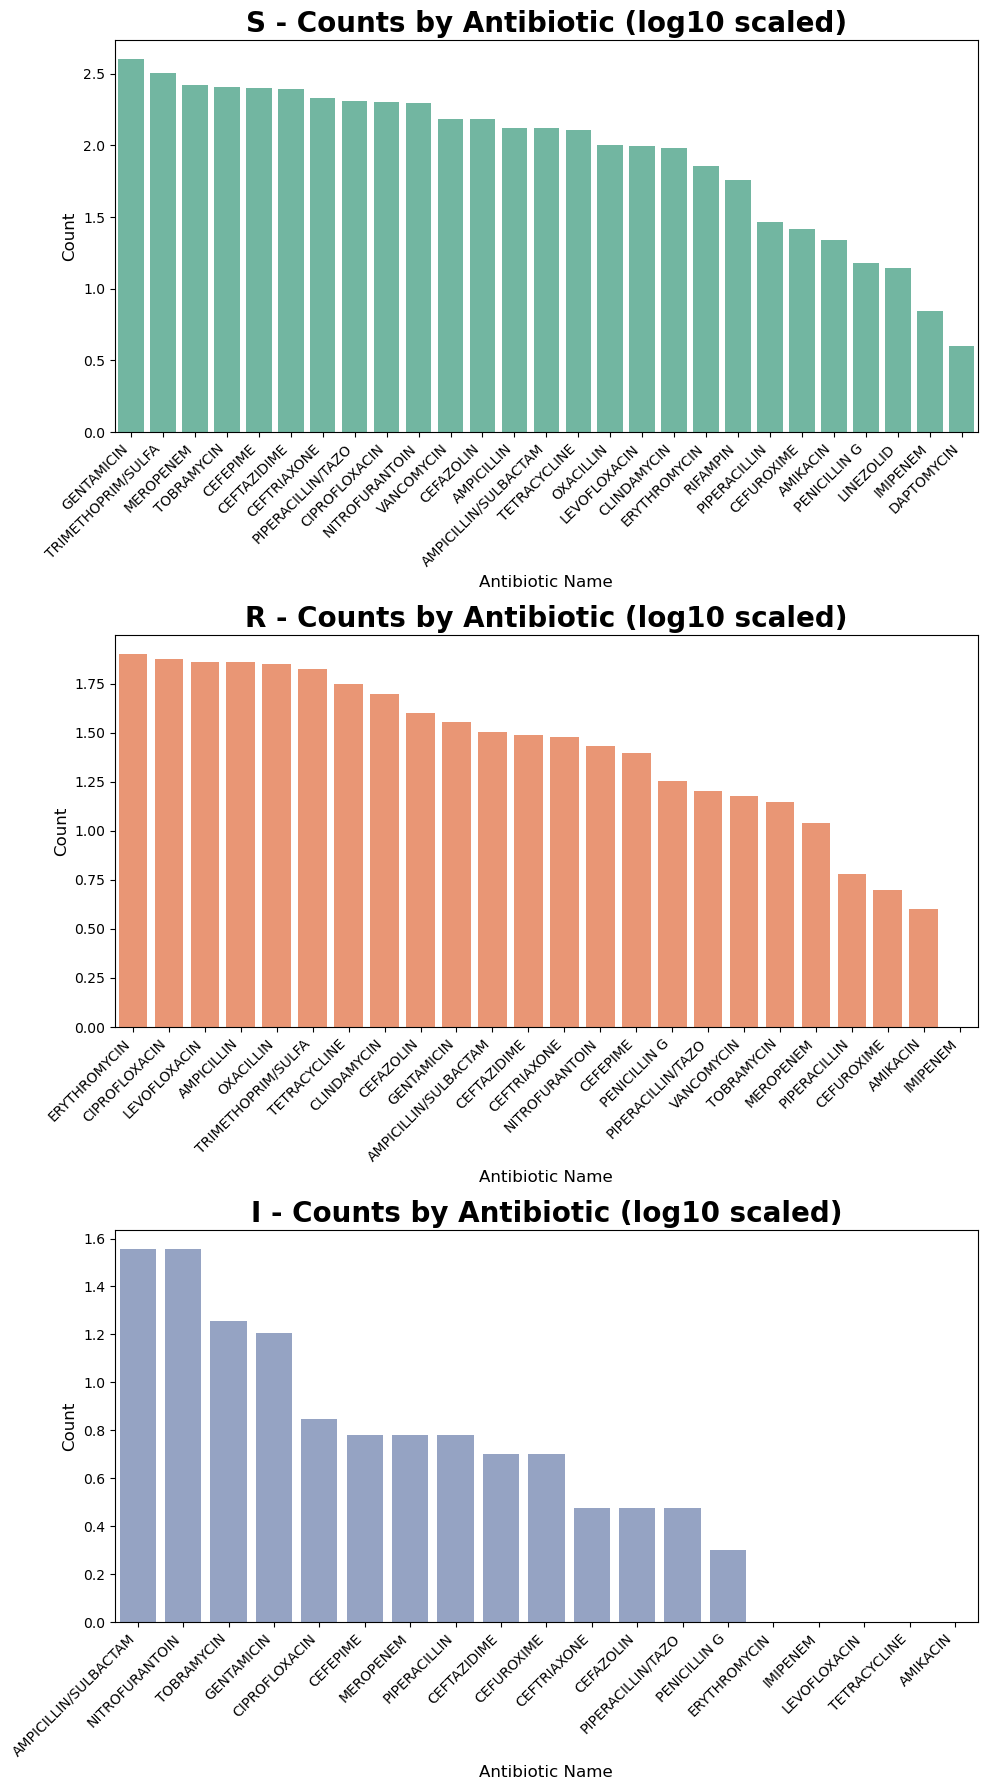

In [28]:
# Get unique interpretations
interpretations = counts_df['interpretation'].unique()
n_interpretations = len(interpretations)

# Create subplots - one for each interpretation
fig, axes = plt.subplots(n_interpretations, 1, figsize=(10,  6* n_interpretations))

# Handle case of single interpretation
if n_interpretations == 1:
    axes = [axes]

# Create a plot for each interpretation
for idx, interpretation in enumerate(interpretations):
    # Filter data for this interpretation
    subset = counts_df[counts_df['interpretation'] == interpretation]
    
    # Sort by count in descending order
    subset = subset.sort_values('count', ascending=False)
    
    # Create barplot
    sns.barplot(
        data=subset,
        x='ab_name',
        y='count',
        ax=axes[idx],
        color=sns.color_palette('Set2')[idx % 10],
        order=subset['ab_name']  # Explicitly set the order
    )
    
    # Customize the subplot
    axes[idx].set_title(f'{interpretation} - Counts by Antibiotic (log10 scaled)', 
                        fontsize=20, fontweight='bold')
    axes[idx].set_xlabel('Antibiotic Name', fontsize=12)
    axes[idx].set_ylabel('Count', fontsize=12)
    
    # Rotate x-axis labels
    axes[idx].tick_params(axis='x', rotation=45)
    plt.setp(axes[idx].xaxis.get_majorticklabels(), ha='right')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()